# 🌿 Spinach Leaf Classification — MobileNetV2
**Goal:** Classify spinach leaf images as **BIG LEAF** or **SMALL LEAF**

## Folder Structure
```
D:\Spinach_Leaf_Classification\
├── dataset\
│   └── model_ready\             ← Already created by Custom CNN notebook
│
├── models\
│   └── mobilenet_best.pth       ← Saved after Cell 3
│
└── results\
    └── mobilenet\               ← ALL MobileNet results here
        ├── history.json
        ├── training_curves.png
        ├── confusion_matrix.png
        └── results_summary.csv
```



## Cell 1 — Imports, Paths & DataLoaders

In [2]:
import json
import time
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ── PATHS ──────────────────────────────────────────────────
ROOT       = Path(r"D:\Spinach_Leaf_Classification")
DATA_DIR   = ROOT / "dataset" / "model_ready"
MODELS     = ROOT / "models"
RESULTS    = ROOT / "results"
MN_RESULTS = RESULTS / "mobilenet"   # all MobileNet outputs go here

MODELS.mkdir(exist_ok=True)
MN_RESULTS.mkdir(parents=True, exist_ok=True)

# ── SETTINGS ───────────────────────────────────────────────
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS     = 30
LR         = 1e-4
PATIENCE   = 5
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# ── TRANSFORMS ─────────────────────────────────────────────
# MobileNetV2 expects ImageNet normalisation
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# ── DATASETS & LOADERS ─────────────────────────────────────
train_ds = datasets.ImageFolder(DATA_DIR / "train",      transform=train_tf)
val_ds   = datasets.ImageFolder(DATA_DIR / "validation", transform=val_test_tf)
test_ds  = datasets.ImageFolder(DATA_DIR / "test",       transform=val_test_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

class_indices = train_ds.class_to_idx
print("Classes:", class_indices)
print("Train:", len(train_ds), "| Val:", len(val_ds), "| Test:", len(test_ds))

# Save class indices
ci_df = pd.DataFrame(list(class_indices.items()), columns=["class_name", "class_index"])
ci_df.to_csv(RESULTS / "class_indices.csv", index=False)
print("Cell 1 complete.")

Device: cuda
Classes: {'Big': 0, 'Small': 1}
Train: 510 | Val: 45 | Test: 45
Cell 1 complete.


## Cell 2 — Build MobileNetV2 Model

In [3]:
# ── LOAD PRETRAINED MobileNetV2 ────────────────────────────
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)

# Freeze all base layers
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last 3 feature blocks for fine-tuning
for param in model.features[-3:].parameters():
    param.requires_grad = True

# Replace classifier head — binary output (Big / Small)
in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 1)   # single logit → BCEWithLogitsLoss
)

model = model.to(DEVICE)

# ── LOSS, OPTIMISER, SCHEDULER ─────────────────────────────
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=3, factor=0.5)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params    : {total_params:,}")
print(f"Trainable params: {trainable_params:,}")
print("Cell 2 complete.")

Total params    : 2,552,065
Trainable params: 1,534,273
Cell 2 complete.


## Cell 3 — Train MobileNetV2


In [4]:
checkpoint_path = MODELS / "mobilenet_best.pth"

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")

for epoch in range(EPOCHS):
    t0 = time.time()

    # ── TRAIN ──
    model.train()
    t_loss, t_correct, t_total = 0.0, 0, 0
    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.float().to(DEVICE).view(-1, 1)
        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        t_loss    += loss.item() * images.size(0)
        preds      = (outputs >= 0).float()
        t_correct += (preds == labels).sum().item()
        t_total   += labels.size(0)

    train_loss = t_loss / t_total
    train_acc  = t_correct / t_total

    # ── VALIDATE ──
    model.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images  = images.to(DEVICE)
            labels  = labels.float().to(DEVICE).view(-1, 1)
            outputs = model(images)
            loss    = criterion(outputs, labels)
            v_loss    += loss.item() * images.size(0)
            preds      = (outputs >= 0).float()
            v_correct += (preds == labels).sum().item()
            v_total   += labels.size(0)

    val_loss = v_loss / v_total
    val_acc  = v_correct / v_total
    scheduler.step(val_loss)
    lr = optimizer.param_groups[0]["lr"]

    # Save best checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)
        print("  checkpoint saved")

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    elapsed = time.time() - t0
    print(
        f"  Epoch {epoch+1:3d}/{EPOCHS} | "
        f"Train {train_acc*100:.1f}% {train_loss:.4f}  |  "
        f"Val {val_acc*100:.1f}% {val_loss:.4f}  |  "
        f"LR {lr:.2e}  |  {elapsed:.1f}s"
    )

model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
print("\nBest checkpoint loaded:", checkpoint_path)

# Save history
with open(MN_RESULTS / "history.json", "w") as f:
    json.dump(history, f)
print("History saved to:", MN_RESULTS / "history.json")
print("Cell 3 complete.")

  checkpoint saved
  Epoch   1/30 | Train 80.6% 0.4902  |  Val 84.4% 0.3560  |  LR 1.00e-04  |  51.1s
  checkpoint saved
  Epoch   2/30 | Train 91.6% 0.2168  |  Val 91.1% 0.2191  |  LR 1.00e-04  |  49.8s
  checkpoint saved
  Epoch   3/30 | Train 93.5% 0.1504  |  Val 91.1% 0.1734  |  LR 1.00e-04  |  51.3s
  Epoch   4/30 | Train 95.1% 0.1164  |  Val 86.7% 0.1909  |  LR 1.00e-04  |  50.7s
  Epoch   5/30 | Train 96.7% 0.0930  |  Val 88.9% 0.1750  |  LR 1.00e-04  |  50.0s
  Epoch   6/30 | Train 98.0% 0.0747  |  Val 88.9% 0.2069  |  LR 1.00e-04  |  51.0s
  Epoch   7/30 | Train 98.2% 0.0494  |  Val 88.9% 0.2270  |  LR 5.00e-05  |  52.4s
  Epoch   8/30 | Train 99.4% 0.0451  |  Val 88.9% 0.1751  |  LR 5.00e-05  |  52.2s
  Epoch   9/30 | Train 99.0% 0.0326  |  Val 88.9% 0.1961  |  LR 5.00e-05  |  50.6s
  Epoch  10/30 | Train 97.8% 0.0528  |  Val 88.9% 0.1925  |  LR 5.00e-05  |  49.4s
  Epoch  11/30 | Train 99.4% 0.0275  |  Val 86.7% 0.2662  |  LR 2.50e-05  |  50.8s
  Epoch  12/30 | Train 98.2% 0

## Cell 4 — Load Saved Model


In [5]:
# Rebuild model and load saved weights
model = models.mobilenet_v2(weights=None)
in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 1)
)
model.load_state_dict(
    torch.load(MODELS / "mobilenet_best.pth", map_location=DEVICE, weights_only=True)
)
model = model.to(DEVICE)
model.eval()

criterion = nn.BCEWithLogitsLoss()

ci_df         = pd.read_csv(RESULTS / "class_indices.csv")
class_indices = dict(zip(ci_df["class_name"], ci_df["class_index"]))
print("MobileNetV2 loaded. Classes:", class_indices)
print("Cell 4 complete.")

MobileNetV2 loaded. Classes: {'Big': 0, 'Small': 1}
Cell 4 complete.


## Cell 5 — Plot Training Curves

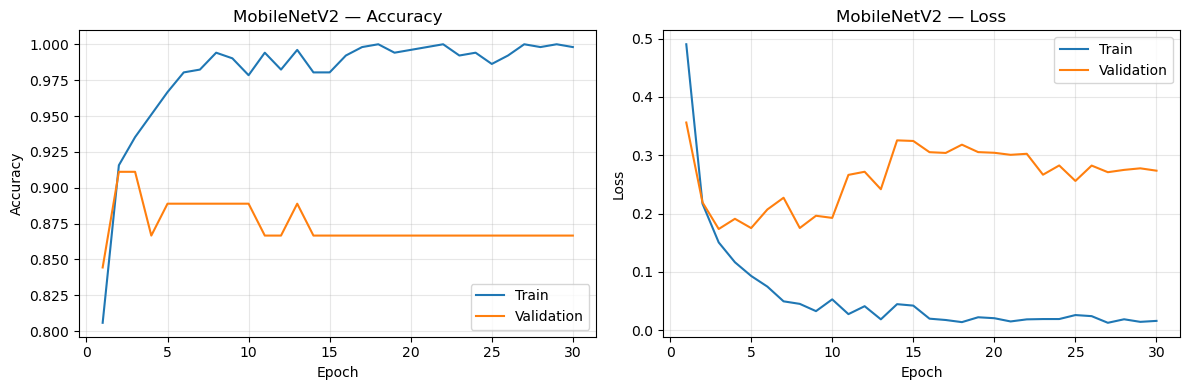

Saved: D:\Spinach_Leaf_Classification\results\mobilenet\training_curves.png
Cell 5 complete.


In [6]:
history_path = MN_RESULTS / "history.json"

if history_path.exists():
    with open(history_path) as f:
        history = json.load(f)

    ep = range(1, len(history["train_acc"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(ep, history["train_acc"], label="Train")
    axes[0].plot(ep, history["val_acc"],   label="Validation")
    axes[0].set_title("MobileNetV2 — Accuracy")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(ep, history["train_loss"], label="Train")
    axes[1].plot(ep, history["val_loss"],   label="Validation")
    axes[1].set_title("MobileNetV2 — Loss")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    save_path = MN_RESULTS / "training_curves.png"
    plt.savefig(save_path, dpi=120)
    plt.show()
    print("Saved:", save_path)
else:
    print("history.json not found. Run Cell 3 first.")

print("Cell 5 complete.")

## Cell 6 — Evaluate on Test Set

MODEL: MobileNetV2
Test images  : 45
Test loss    : 0.1441
Test accuracy: 91.11%

Classification Report:
              precision    recall  f1-score   support

         Big       0.88      0.96      0.92        23
       Small       0.95      0.86      0.90        22

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



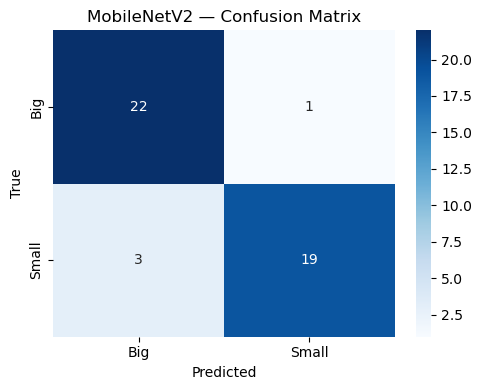

Confusion matrix saved: D:\Spinach_Leaf_Classification\results\mobilenet\confusion_matrix.png
Cell 6 complete.


In [7]:
model.eval()
all_preds, all_labels = [], []
total_loss, total_imgs = 0.0, 0

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(DEVICE)
        labels  = labels.to(DEVICE)
        outputs = model(images)
        loss    = criterion(outputs, labels.float().view(-1, 1))
        probs   = torch.sigmoid(outputs).view(-1)
        preds   = (probs >= 0.5).long()

        total_loss += loss.item() * labels.size(0)
        total_imgs += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = total_loss / total_imgs
test_acc  = accuracy_score(all_labels, all_preds)

idx_to_class = {v: k for k, v in class_indices.items()}
class_names  = [idx_to_class[i] for i in range(len(class_indices))]
pred_names   = [idx_to_class[p] for p in all_preds]
true_names   = [idx_to_class[t] for t in all_labels]

print("=" * 55)
print("MODEL: MobileNetV2")
print("=" * 55)
print(f"Test images  : {total_imgs}")
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc*100:.2f}%")
print("\nClassification Report:")
print(classification_report(true_names, pred_names,
                             labels=class_names, target_names=class_names,
                             zero_division=0))

# Confusion matrix
cm = confusion_matrix(true_names, pred_names, labels=class_names)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("MobileNetV2 — Confusion Matrix")
plt.ylabel("True"); plt.xlabel("Predicted")
plt.tight_layout()
cm_path = MN_RESULTS / "confusion_matrix.png"
plt.savefig(cm_path, dpi=120)
plt.show()
print("Confusion matrix saved:", cm_path)

mn_results = {"model": "MobileNetV2", "test_loss": test_loss, "test_accuracy": test_acc}
print("Cell 6 complete.")

In [1]:
from pathlib import Path
import zipfile

ROOT = Path(r"D:\Spinach_Leaf_Classification")
ZIP_PATH = Path.home() / "Desktop" / "Spinach_Notebooks_For_Audit.zip"

exclude = {".ipynb_checkpoints", ".git", "__pycache__", "venv"}

files_to_include = []

# Collect original notebooks, excluding checkpoint duplicates
for path in ROOT.rglob("*.ipynb"):
    if not any(part in exclude for part in path.parts):
        files_to_include.append(path)

# Collect Python application files
for folder in ["webapp", "web_app"]:
    app_folder = ROOT / folder
    if app_folder.exists():
        for path in app_folder.rglob("*.py"):
            if not any(part in exclude for part in path.parts):
                files_to_include.append(path)

# Include useful class mappings and evaluation summaries
for relative in [
    "results/class_indices.csv",
    "results/previous/class_indices.csv",
    "results/previous/dataset_manifest.csv",
    "results/previous/model_comparison.csv",
]:
    path = ROOT / relative
    if path.exists():
        files_to_include.append(path)

files_to_include = sorted(set(files_to_include))

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zip_file:
    for path in files_to_include:
        zip_file.write(path, path.relative_to(ROOT))

print("Files collected:", len(files_to_include))
for path in files_to_include:
    print(path.relative_to(ROOT))

print("\nZIP created:", ZIP_PATH)

Files collected: 8
models\custom_cnn\custom_CNN_spinach_leaf_classification.ipynb
models\mobilenet\mobilenet_spinach_leaf_classification.ipynb
models\xgboost\xgboost_spinach_leaf_classification.ipynb
results\class_indices.csv
results\previous\class_indices.csv
results\previous\dataset_manifest.csv
results\previous\model_comparison.csv
webapp\gradio_spinach_app.py

ZIP created: C:\Users\CSE_SDPL\Desktop\Spinach_Notebooks_For_Audit.zip
